# 04 · Modelo final

**Pregunta.** ¿Qué variables, qué C y qué umbral tiene el modelo final, el mismo para los tres
cortes?

**Regla de decisión** (E10). El mismo procedimiento que se validó en el notebook 03, ahora con
los tres periodos de entrenamiento:
1. RF y GB con la configuración común de mayor ROC-AUC media sobre los cortes en la búsqueda
   dejando fuera un periodo de tres (`artifacts/search_<modelo>_<corte>.joblib`), ajustados con
   todo el entrenamiento; su importancia por impureza da el orden común de las variables.
2. Búsqueda de (k, C) de la logística L2 dejando fuera cada periodo (tres pliegues), media
   sobre cortes, y regla de un error típico.
3. Umbral de cada corte: el que maximiza F2 en las predicciones fuera de pliegue de esa
   búsqueda. Reajuste con los tres periodos.

Después de este notebook no se cambia nada del modelo. Solo periodos de entrenamiento.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import comun as c  # noqa: E402

import joblib  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.base import clone  # noqa: E402
from sklearn.metrics import fbeta_score, precision_score, recall_score  # noqa: E402

c.thesis_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
data = {cut: c.load_train(cut) for cut in c.CUTS}
Cs = c.GRIDS["lr"]["logisticregression__C"]

## 1. Árboles con la configuración común y orden de las variables

In [2]:
tree_params, imps = {}, {}
for m in ["rf", "gb"]:
    joint = c.joint_table({cut: joblib.load(c.ARTIFACTS / f"search_{m}_{cut}.joblib") for cut in c.CUTS})
    tree_params[m] = joint.loc[0, "params"]
    for cut, d in data.items():
        feats = c.features_for(cut)
        c.thermal_guard()
        model = clone(c.make_model(m)).set_params(**tree_params[m]).fit(d[feats], d[c.TARGET])
        imps[m, cut] = pd.Series(model.feature_importances_, index=feats)
order_s = c.tree_ranking(imps)
order = list(order_s.index)
print(tree_params)
norm = pd.DataFrame({k: v / v.sum() for k, v in imps.items()}).reindex(order)
norm.assign(media=order_s).rename(index=c.LABEL)

[pausa térmica: CPU a 83 °C]


[pausa térmica: CPU a 81 °C]


[pausa térmica: CPU a 81 °C]


[pausa térmica: CPU a 82 °C]


{'rf': {'min_samples_leaf': 50, 'max_features': 'sqrt'}, 'gb': {'learning_rate': 0.02, 'max_depth': 3, 'n_estimators': 300}}


rf                           gb                        media
                                   first        mid       last  first        mid       last       
mean_score_with_zeros (valor)      0.308  2.325e-01  2.647e-01  0.701  4.195e-01  7.834e-01  0.452
last_score (valor)                   NaN  2.257e-01  8.188e-02    NaN  4.292e-01  1.603e-02  0.188
mean_score_with_zeros (percentil)  0.251  1.279e-01  1.581e-01  0.098  6.047e-03  1.481e-02  0.109
recent_clicks_28d                  0.087  7.518e-02  1.454e-01  0.060  5.911e-02  1.068e-01  0.089
days_since_last_activity           0.082  6.123e-02  1.405e-01  0.067  5.368e-02  4.669e-02  0.075
submission_rate                    0.113  7.668e-02  9.314e-02  0.006  1.265e-02  1.641e-02  0.053
last_score (percentil)               NaN  1.364e-01  5.748e-02    NaN  7.008e-03  6.410e-03  0.052
active_days                        0.058  2.823e-02  2.762e-02  0.021  4.069e-03  2.454e-03  0.024
n_unique_sites                     0.031  1.068e-02  1.681e-02  0.013  2.256e-03  2.718e-03  0.013
total_clicks                       0.034  1.711e-02  9.540e-03  0.010  2.671e-03  1.808e-03  0.012
pre_course_clicks                  0.017  4.135e-03  2.477e-03  0.008  1.951e-03  1.276e-03  0.006
clicks_per_active_day              0.015  3.764e-03  2.294e-03  0.005  1.405e-03  8.786e-04  0.005
repeated_course                    0.005  3.969e-04  1.501e-04  0.012  4.493e-04  3.172e-04  0.003

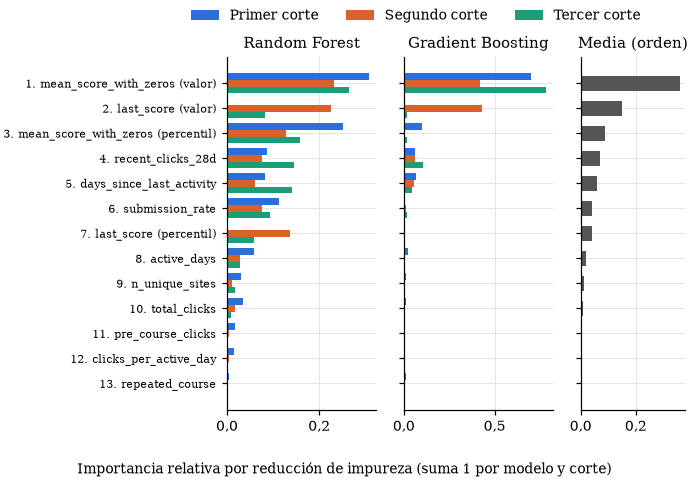

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(6.5, 4.2), sharey=True, gridspec_kw={"width_ratios": [1, 1, 0.7]})
y = np.arange(len(order))
w = 0.27
for ax, m, title in [(axes[0], "rf", "Random Forest"), (axes[1], "gb", "Gradient Boosting")]:
    for j, cut in enumerate(c.CUTS):
        ax.barh(y + (j - 1) * w, norm[(m, cut)].fillna(0), height=w, color=c.CUT_COLORS[cut], label=c.CUT_NAMES[cut])
    ax.set_title(title)
    c.comma_axis(ax, "x", 1)
axes[2].barh(y, order_s.values, height=0.6, color="#555555")
axes[2].set_title("Media (orden)")
c.comma_axis(axes[2], "x", 1)
axes[0].set_yticks(y, [f"{i + 1}. {c.LABEL[f]}" for i, f in enumerate(order)], fontsize=7.5)
axes[0].invert_yaxis()
handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, ncols=3, loc="upper center", bbox_to_anchor=(0.6, 1.05))
fig.supxlabel("Importancia relativa por reducción de impureza (suma 1 por modelo y corte)", fontsize=9)
fig.tight_layout()
c.save_figure(fig, "importancias_arboles")
plt.show()

## 2. Búsqueda de (k, C) con los tres periodos y regla de un error típico

In [4]:
path = c.ARTIFACTS / "sel_final.joblib"
search = joblib.load(path) if path.exists() else None
if search is None or set(Cs) - set(search["C"]):
    search = c.selection_search(data, order, Cs, previous=search)
    joblib.dump(search, path)
search = search[search["C"].isin(Cs)].reset_index(drop=True)  # grilla de C de E13
choice = c.one_se_choice(search)
K, C = int(choice["k"]), float(choice["C"])
choice

k            4.000
C            0.001
2013B        0.894
2013J        0.888
2014B        0.880
auc          0.888
se           0.005
best_auc     0.890
best_k      13.000
Name: 33, dtype: float64

In [5]:
best_per_k = search.loc[search.groupby("k")["auc"].idxmax()].set_index("k")
best_per_k

,C,2013B,2013J,2014B,auc
k,,,,,
1,0.001,0.887,0.877,0.859,0.874
2,30.000,0.887,0.881,0.861,0.876
3,0.010,0.891,0.881,0.865,0.879
4,0.001,0.894,0.888,0.880,0.888
5,0.001,0.894,0.889,0.885,0.889
6,0.030,0.896,0.889,0.880,0.888
7,0.100,0.896,0.889,0.880,0.888
8,0.100,0.896,0.890,0.880,0.889
9,0.100,0.896,0.890,0.880,0.889


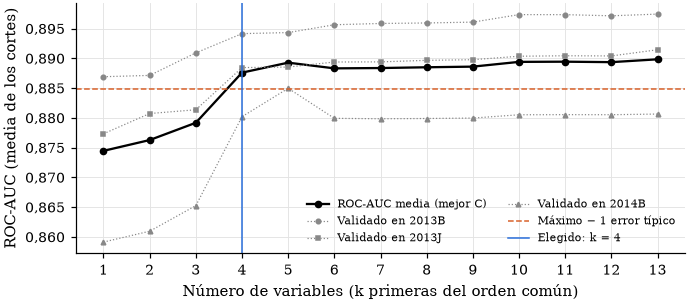

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.plot(best_per_k.index, best_per_k["auc"], marker="o", ms=4, color="black", label="ROC-AUC media (mejor C)")
for p, mk in zip(c.TRAIN_PERIODS, ["o", "s", "^"]):
    ax.plot(best_per_k.index, best_per_k[p], ls=":", marker=mk, ms=3, lw=0.8, color="#888888", label=f"Validado en {p}")
ax.axhline(choice["best_auc"] - choice["se"], color="#d9622b", ls="--", lw=1, label="Máximo − 1 error típico")
ax.axvline(K, color="#2a6fdb", lw=1, label=f"Elegido: k = {K}")
ax.set_xticks(best_per_k.index)
ax.set_xlabel("Número de variables (k primeras del orden común)")
ax.set_ylabel("ROC-AUC (media de los cortes)")
c.comma_axis(ax, "y", 3)
ax.legend(fontsize=7, loc="lower right", ncols=2)
fig.tight_layout()
c.save_figure(fig, "seleccion_k")
plt.show()

## 3. Umbral F2 y ajuste final

In [7]:
final, rows = {}, []
for cut, d in data.items():
    feats = c.top_k(order, K, cut)
    model = c.make_model("lr").set_params(logisticregression__C=C)
    oof = c.lopo_oof(model, d, feats)
    thr = c.f2_threshold(d[c.TARGET], oof)
    yhat = oof >= thr
    y = d[c.TARGET]
    rows.append({"corte": cut, "variables": len(feats), "umbral": thr, "sensibilidad (fuera de pliegue)": recall_score(y, yhat),
                 "precisión": precision_score(y, yhat), "F2": fbeta_score(y, yhat, beta=2), "marcados (%)": 100 * yhat.mean()})
    c.thermal_guard()
    fitted = clone(model).fit(d[feats], y)
    final[cut] = {"model": fitted, "features": feats, "C": C, "threshold": thr, "oof": oof}
    joblib.dump(final[cut], c.ARTIFACTS / f"final_{cut}.joblib")
summary = pd.DataFrame(rows).set_index("corte")
summary

,variables,umbral,sensibilidad (fuera de pliegue),precisión,F2,marcados (%)
corte,,,,,,
first,3,0.213,0.943,0.504,0.803,81.059
mid,4,0.235,0.901,0.636,0.831,55.088
last,4,0.263,0.906,0.699,0.856,45.731


In [8]:
coef = pd.DataFrame({c.CUT_NAMES[cut]: pd.Series(f["model"][-1].coef_[0], index=f["features"]) for cut, f in final.items()}
                    ).reindex(c.top_k(order, K, "last"))
coef.rename(index=c.LABEL)

,Primer corte,Segundo corte,Tercer corte
mean_score_with_zeros (valor),-0.489,-0.467,-0.614
last_score (valor),NaN,-0.537,-0.438
mean_score_with_zeros (percentil),-0.497,-0.457,-0.575
recent_clicks_28d,-0.406,-0.510,-0.588


In [9]:
c.save_json({"tree_params": tree_params, "order": order, "order_importance": order_s.to_dict(),
             "choice": choice.to_dict(), "summary": summary.reset_index().to_dict("records"),
             "coef": coef.to_dict()}, c.ARTIFACTS / "04_modelo_final.json")

## Conclusiones

- **Orden común** (RF con hojas de 50 y √p; GB con 0,02 · profundidad 3 · 300 árboles): la nota
  media (valor), `last_score` (valor), la nota media (percentil) y la actividad reciente, por
  este orden; las de VLE salvo la actividad reciente y la recencia pesan poco.
- **Selección**: el máximo de la búsqueda está en k = 13 (0,890), pero desde k = 4 la curva es
  plana dentro de un error típico (0,005). **k = 4, C = 0,001.**
- **Modelo final (E14)**: logística L2 con `mean_score_with_zeros` en valor y en percentil,
  `last_score` en valor (no en el primer corte) y `recent_clicks_28d`; mismo C en los tres
  cortes. Umbral F2: 0,213 · 0,235 · 0,263. Fuera de pliegue detecta al 94 % · 90 % · 91 % de
  los estudiantes en riesgo y marca al 81 % · 55 % · 46 %. Todos los coeficientes, negativos
  (más nota o más actividad reciente, menos riesgo). No se cambia más.